# Part 2 — Supervised learning baseline: Naive Bayes vs. decision tree

**Project:** Predict Students' Dropout and Academic Success (UCI dataset 697, CC BY 4.0). **Task:** three-class classification (`Dropout`, `Enrolled`, `Graduate`) from information available by the end of semester 2. **Primary metric:** macro F1, with accuracy, balanced accuracy, one-vs-rest ROC-AUC and per-class recall alongside it.

This notebook extends Part 1. Section 0 restates the Part 1 split and preprocessing unchanged. Part 2 then

1. trains two Naive Bayes variants and a decision tree, each with the preprocessing **inside** its pipeline so every cross-validation fold learns its own imputation, clipping, scaling and encoding;
2. works one information-gain / Gini split through by hand from the project data;
3. compares the models with repeated stratified cross-validation on the training partition, using nested cross-validation for the tuned tree so tuning does not inflate its score;
4. evaluates the held-out test set once, after all model choices are fixed, and discusses the results.

## 0. Setup — Part 1 split and preprocessing (unchanged)

In [1]:
import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, make_scorer, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, train_test_split, validation_curve)
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore', message='Bins whose width are too small')
SEED = 42
CLASSES = ['Dropout', 'Enrolled', 'Graduate']
COLORS = {'Dropout': '#be5550', 'Enrolled': '#d7aa3f', 'Graduate': '#4b8a72'}

def locate_data():
    for path in (Path('../data.csv'), Path('data.csv')):
        if path.exists():
            return path
    raise FileNotFoundError('Run from assignment 2/ or the repository root; data.csv is required')

data = pd.read_csv(locate_data())
assert data.shape == (4424, 37)
X = data.drop(columns='Target')
y = data['Target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)  # identical to Part 1
print('Training/test rows:', len(X_train), len(X_test))
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).loc[CLASSES])

Training/test rows: 3539 885


,train,test
Target,,
Dropout,1137,284
Enrolled,635,159
Graduate,1767,442


In [2]:
class AcademicFeatures(BaseEstimator, TransformerMixin):
    """Per-semester approval rates; a zero denominator becomes NaN and is imputed downstream."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        out = X.copy()
        for semester in ('1st', '2nd'):
            prefix = f'Curricular units {semester} sem'
            denominator = out[f'{prefix} (enrolled)'].replace(0, np.nan)
            out[f'{semester} approval rate'] = out[f'{prefix} (approved)'] / denominator
        return out


class IQRClipper(BaseEstimator, TransformerMixin):
    """Clip to training-fitted Tukey fences."""
    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(values, [25, 75], axis=0)
        spread = q3 - q1
        self.lower_ = np.where(spread > 0, q1 - 1.5 * spread, -np.inf)
        self.upper_ = np.where(spread > 0, q3 + 1.5 * spread, np.inf)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


categorical = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality', "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
]
binary = [
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date',
    'Gender', 'Scholarship holder', 'International',
]
constructed = ['1st approval rate', '2nd approval rate']
numeric = [c for c in X_train.columns if c not in categorical + binary] + constructed


def continuous_preprocessing():
    """Part 1 preprocessing: median impute, IQR clip, robust scale; one-hot categories."""
    return Pipeline([
        ('features', AcademicFeatures()),
        ('preprocess', ColumnTransformer([
            ('numeric', Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('clip', IQRClipper()),
                ('scale', RobustScaler())]), numeric),
            ('categorical', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
            ('binary', SimpleImputer(strategy='most_frequent'), binary),
        ], remainder='drop')),
    ])


def binned_preprocessing(n_bins=5):
    """All-binary representation for Bernoulli Naive Bayes: numeric features become quantile bins."""
    return Pipeline([
        ('features', AcademicFeatures()),
        ('preprocess', ColumnTransformer([
            ('numeric', Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('bins', KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile'))]), numeric),
            ('categorical', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
            ('binary', SimpleImputer(strategy='most_frequent'), binary),
        ], remainder='drop')),
    ])


def numeric_only_preprocessing():
    """Continuous features only, for Gaussian Naive Bayes (no 0/1 or one-hot columns)."""
    return Pipeline([
        ('features', AcademicFeatures()),
        ('preprocess', ColumnTransformer([
            ('numeric', Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('clip', IQRClipper()),
                ('scale', RobustScaler())]), numeric),
        ], remainder='drop')),
    ])


def with_model(preprocessing, model):
    return Pipeline([('prep', preprocessing), ('model', model)])

Xp = continuous_preprocessing().fit_transform(X_train)
Xb = binned_preprocessing().fit_transform(X_train)
print('Continuous representation:', Xp.shape, '| binned/binary representation:', Xb.shape,
      '| numeric-only representation:', numeric_only_preprocessing().fit_transform(X_train).shape)

Continuous representation: (3539, 239) | binned/binary representation: (3539, 299) | numeric-only representation: (3539, 21)


### 1.1 Why Gaussian NB on the full Part 1 matrix is expected to struggle

Gaussian NB models each feature as a normal distribution within each class. Most columns of the Part 1 matrix are one-hot indicators that are 0 for nearly every student, so their within-class variance is tiny and the fitted normal is extremely narrow. The diagnostic below measures this directly instead of assuming it.

In [3]:
diag_all = with_model(continuous_preprocessing(), GaussianNB()).fit(X_train, y_train)
diag_num = with_model(numeric_only_preprocessing(), GaussianNB()).fit(X_train, y_train)
var_all = diag_all.named_steps['model'].var_
var_num = diag_num.named_steps['model'].var_
print(f'All features:     {var_all.shape[1]} columns, median within-class variance = {np.median(var_all):.2e}, '
      f'{(var_all < 1e-3).mean():.0%} of (class, column) variances are < 1e-3')
print(f'Numeric features: {var_num.shape[1]} columns, median within-class variance = {np.median(var_num):.2e}, '
      f'{(var_num < 1e-3).mean():.0%} of (class, column) variances are < 1e-3')

All features:     239 columns, median within-class variance = 3.38e-03, 34% of (class, column) variances are < 1e-3
Numeric features: 21 columns, median within-class variance = 5.66e-01, 0% of (class, column) variances are < 1e-3


## 1. Models

| Model | Representation | Why it is included |
|---|---|---|
| Majority-class `DummyClassifier` | none | Reference point: what a model that ignores the features scores. |
| **Gaussian NB (all features)** | Part 1 output: robust-scaled numeric + one-hot + binary | The standard NB variant for continuous features, fed the full Part 1 matrix. Included because it is the obvious first attempt; Section 1.1 diagnoses why it fails. |
| **Gaussian NB (numeric only)** | Only the continuous/count columns (incl. the two approval rates), robust-scaled | The fair Gaussian variant: normality is at least plausible for these inputs, and no 0/1 columns are modelled as Gaussians. |
| **Bernoulli Naive Bayes** | Quantile-binned numerics (5 bins) + one-hot + binary, all 0/1 | Fits the 0/1 and categorical columns natively and makes no normality assumption. |
| **Decision tree, unpruned** | Part 1 output | Shows how a fully grown tree overfits. |
| **Decision tree, tuned** | Part 1 output | `criterion`, `max_depth`, `min_samples_leaf` and `class_weight` chosen by an inner 3-fold search on macro F1. |

Trees need no scaling but share the Part 1 representation so the comparison differs only in the model. Naive Bayes has no tuned hyperparameters beyond the library defaults (`var_smoothing=1e-9`, `alpha=1`).

## 2. Hand-worked split: information gain and Gini

We fit a depth-1 decision tree (a *stump*) on the **raw** training columns with `criterion='entropy'` and let scikit-learn choose the best root split. Then we recompute that split's information gain and Gini decrease from the class counts alone, using the formulas

$$H(S) = -\sum_k p_k \log_2 p_k, \qquad \mathrm{IG} = H(S) - \sum_{c \in \{L,R\}} \frac{|S_c|}{|S|} H(S_c), \qquad G(S) = 1 - \sum_k p_k^2, \qquad \Delta G = G(S) - \sum_c \frac{|S_c|}{|S|} G(S_c).$$

Scikit-learn is used only to *propose* the candidate split and to *verify* the arithmetic at the end.

In [4]:
stump = DecisionTreeClassifier(criterion='entropy', max_depth=1, random_state=SEED).fit(X_train, y_train)
feature = X_train.columns[stump.tree_.feature[0]]
threshold = stump.tree_.threshold[0]
print(f'Root split chosen by the stump:  "{feature}" <= {threshold:.1f}')

left = (X_train[feature] <= threshold).to_numpy()
table = pd.DataFrame({
    f'left  ({feature} <= {threshold:.1f})': y_train[left].value_counts(),
    f'right ({feature} >  {threshold:.1f})': y_train[~left].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
table['parent'] = table.sum(axis=1)
table.loc['total'] = table.sum()
display(table)

Root split chosen by the stump:  "Curricular units 2nd sem (approved)" <= 3.5


,left (Curricular units 2nd sem (approved) <= 3.5),right (Curricular units 2nd sem (approved) > 3.5),parent
Target,,,
Dropout,844,293,1137
Enrolled,235,400,635
Graduate,96,1671,1767
total,1175,2364,3539


In [5]:
def show_entropy(counts, name):
    counts = np.asarray(counts, dtype=float)
    n = counts.sum()
    p = counts / n
    terms = ' + '.join(f'{pk:.4f}*log2({pk:.4f})' for pk in p if pk > 0)
    value = -sum(pk * np.log2(pk) for pk in p if pk > 0)
    print(f'H({name}) = -[{terms}] = {value:.4f} bits   (n = {int(n)})')
    return value

def show_gini(counts, name):
    counts = np.asarray(counts, dtype=float)
    n = counts.sum()
    p = counts / n
    terms = ' + '.join(f'{pk:.4f}^2' for pk in p)
    value = 1 - (p ** 2).sum()
    print(f'G({name}) = 1 - [{terms}] = {value:.4f}')
    return value

parent = table.loc[CLASSES, 'parent'].to_numpy()
child = {side: table.loc[CLASSES, col].to_numpy() for side, col in zip('LR', table.columns[:2])}
n, nL, nR = parent.sum(), child['L'].sum(), child['R'].sum()

print('--- Step 1: entropy of the parent and each child ---')
H_parent = show_entropy(parent, 'parent')
H_left = show_entropy(child['L'], 'left')
H_right = show_entropy(child['R'], 'right')
print()
print('--- Step 2: weighted child entropy and information gain ---')
H_children = nL / n * H_left + nR / n * H_right
IG = H_parent - H_children
print(f'weighted child entropy = {nL}/{n}*{H_left:.4f} + {nR}/{n}*{H_right:.4f} = {H_children:.4f}')
print(f'IG = {H_parent:.4f} - {H_children:.4f} = {IG:.4f} bits')
print()
print('--- Step 3: the same split under Gini ---')
G_parent = show_gini(parent, 'parent')
G_left = show_gini(child['L'], 'left')
G_right = show_gini(child['R'], 'right')
G_children = nL / n * G_left + nR / n * G_right
dG = G_parent - G_children
print(f'weighted child Gini = {nL}/{n}*{G_left:.4f} + {nR}/{n}*{G_right:.4f} = {G_children:.4f}')
print(f'Delta Gini = {G_parent:.4f} - {G_children:.4f} = {dG:.4f}')

tree = stump.tree_
sk_ig = tree.impurity[0] - (tree.n_node_samples[1] * tree.impurity[1] + tree.n_node_samples[2] * tree.impurity[2]) / tree.n_node_samples[0]
gini_stump = DecisionTreeClassifier(criterion='gini', max_depth=1, random_state=SEED).fit(X_train, y_train)
gt = gini_stump.tree_
sk_dg = gt.impurity[0] - (gt.n_node_samples[1] * gt.impurity[1] + gt.n_node_samples[2] * gt.impurity[2]) / gt.n_node_samples[0]
print()
print(f'Check against scikit-learn: IG = {sk_ig:.4f} (hand {IG:.4f}).')
print(f'A Gini-criterion stump picks "{X_train.columns[gt.feature[0]]}" <= {gt.threshold[0]:.1f} '
      f'with Delta Gini = {sk_dg:.4f}; the entropy-chosen split scores Delta Gini = {dG:.4f} under Gini.')
assert np.isclose(IG, sk_ig)
assert X_train.columns[gt.feature[0]] == feature      # same feature ...
assert dG <= sk_dg + 1e-12                            # ... and Gini's own optimum cannot be worse than ours

--- Step 1: entropy of the parent and each child ---
H(parent) = -[0.3213*log2(0.3213) + 0.1794*log2(0.1794) + 0.4993*log2(0.4993)] = 1.4713 bits   (n = 3539)
H(left) = -[0.7183*log2(0.7183) + 0.2000*log2(0.2000) + 0.0817*log2(0.0817)] = 1.1025 bits   (n = 1175)
H(right) = -[0.1239*log2(0.1239) + 0.1692*log2(0.1692) + 0.7069*log2(0.7069)] = 1.1608 bits   (n = 2364)

--- Step 2: weighted child entropy and information gain ---
weighted child entropy = 1175/3539*1.1025 + 2364/3539*1.1608 = 1.1415
IG = 1.4713 - 1.1415 = 0.3299 bits

--- Step 3: the same split under Gini ---
G(parent) = 1 - [0.3213^2 + 0.1794^2 + 0.4993^2] = 0.6153
G(left) = 1 - [0.7183^2 + 0.2000^2 + 0.0817^2] = 0.4374
G(right) = 1 - [0.1239^2 + 0.1692^2 + 0.7069^2] = 0.4564
weighted child Gini = 1175/3539*0.4374 + 2364/3539*0.4564 = 0.4501
Delta Gini = 0.6153 - 0.4501 = 0.1652

Check against scikit-learn: IG = 0.3299 (hand 0.3299).
A Gini-criterion stump picks "Curricular units 2nd sem (approved)" <= 4.5 with Delta Gini =

**Reading the worked case.** The parent node's entropy is close to the log2(3) = 1.585-bit maximum for three classes because Graduate, Dropout and Enrolled are all common. The split sends most Dropout and Enrolled students to one side and most Graduates to the other, so both children are purer than the parent; the information gain is the entropy that this purification removes. The Gini decrease tells a similar story on a different scale. The two criteria agree on the **feature** (second-semester approved units) but not on the **threshold**: entropy prefers the cut after 3 approved units, the Gini stump the cut after 4. Because the entropy-chosen split is not the Gini optimum, its hand-computed Gini decrease is slightly *smaller* than the Gini stump's, which is exactly what the final assertion checks. This is one reason `criterion` is treated as a tuned hyperparameter later. The information-gain arithmetic is asserted to match scikit-learn's own impurity bookkeeping.

## 3. Evaluation design

* **Cross-validation:** 5-fold stratified, repeated 3 times (15 folds) on the **training** partition only, with the identical fold assignments for every model so scores can be compared pairwise. Stratification keeps the 18 % `Enrolled` class in every fold.
* **Metrics:** macro F1 (primary; every class counts equally), accuracy, balanced accuracy, one-vs-rest macro ROC-AUC (threshold-free ranking quality, needs `predict_proba`), and per-class recall to expose the minority class. Accuracy alone would flatter a model that ignores `Enrolled`.
* **Leakage control:** preprocessing lives inside each pipeline, so every fold fits its own imputers, clip fences, scalers and encoders on that fold's training rows. The tuned tree is evaluated with **nested** CV: its grid search runs inside each outer training fold, so the outer score is not selected on the data it is measured on.
* **Test set:** untouched until Section 6.

In [6]:
def class_recall(y_true, y_pred, label):
    return recall_score(y_true, y_pred, labels=[label], average='macro', zero_division=0)

SCORING = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro',
    'roc_auc_ovr': 'roc_auc_ovr',
    **{f'recall_{c}': make_scorer(class_recall, label=c) for c in CLASSES},
}
OUTER_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

TREE_GRID = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 4, 6, 8],
    'model__min_samples_leaf': [1, 10, 30],
    'model__class_weight': [None, 'balanced'],
}

def tuned_tree_search(cv=3):
    return GridSearchCV(
        with_model(continuous_preprocessing(), DecisionTreeClassifier(random_state=SEED)),
        TREE_GRID, scoring='f1_macro', cv=StratifiedKFold(cv, shuffle=True, random_state=SEED),
        n_jobs=1, refit=True)

MODELS = {
    'Majority class (reference)': with_model(continuous_preprocessing(), DummyClassifier(strategy='most_frequent')),
    'Gaussian NB (all features)': with_model(continuous_preprocessing(), GaussianNB()),
    'Gaussian NB (numeric only)': with_model(numeric_only_preprocessing(), GaussianNB()),
    'Bernoulli Naive Bayes (binned)': with_model(binned_preprocessing(), BernoulliNB(binarize=None)),
    'Decision tree (unpruned)': with_model(continuous_preprocessing(), DecisionTreeClassifier(random_state=SEED)),
    'Decision tree (tuned, nested CV)': tuned_tree_search(),
}

results = {}
for name, estimator in MODELS.items():
    results[name] = cross_validate(estimator, X_train, y_train, cv=OUTER_CV, scoring=SCORING,
                                   return_train_score=False, n_jobs=-1)
    print(f'{name:36s} macro F1 = {results[name]["test_f1_macro"].mean():.4f} '
          f'(+/- {results[name]["test_f1_macro"].std():.4f})  fit time/fold = {results[name]["fit_time"].mean():.2f}s')

Majority class (reference)           macro F1 = 0.2220 (+/- 0.0002)  fit time/fold = 0.12s


Gaussian NB (all features)           macro F1 = 0.2167 (+/- 0.0100)  fit time/fold = 0.12s


Gaussian NB (numeric only)           macro F1 = 0.6506 (+/- 0.0121)  fit time/fold = 0.05s


Bernoulli Naive Bayes (binned)       macro F1 = 0.6709 (+/- 0.0127)  fit time/fold = 0.14s


Decision tree (unpruned)             macro F1 = 0.6265 (+/- 0.0129)  fit time/fold = 0.20s


Decision tree (tuned, nested CV)     macro F1 = 0.6755 (+/- 0.0154)  fit time/fold = 22.40s


In [7]:
METRICS = ['accuracy', 'balanced_accuracy', 'f1_macro', 'roc_auc_ovr'] + [f'recall_{c}' for c in CLASSES]
summary = pd.DataFrame({
    name: {m: f'{r[f"test_{m}"].mean():.3f} ± {r[f"test_{m}"].std():.3f}' for m in METRICS}
    for name, r in results.items()
}).T
summary.columns = ['Accuracy', 'Balanced acc.', 'Macro F1', 'ROC-AUC (OvR)', 'Recall Dropout', 'Recall Enrolled', 'Recall Graduate']
print('Mean ± standard deviation over 15 stratified CV folds (training partition only)')
display(summary)

Mean ± standard deviation over 15 stratified CV folds (training partition only)


,Accuracy,Balanced acc.,Macro F1,ROC-AUC (OvR),Recall Dropout,Recall Enrolled,Recall Graduate
Majority class (reference),0.499 ± 0.001,0.333 ± 0.000,0.222 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Gaussian NB (all features),0.241 ± 0.008,0.385 ± 0.011,0.217 ± 0.010,0.704 ± 0.012,0.213 ± 0.023,0.933 ± 0.029,0.009 ± 0.005
Gaussian NB (numeric only),0.714 ± 0.012,0.647 ± 0.012,0.651 ± 0.012,0.827 ± 0.014,0.617 ± 0.026,0.454 ± 0.028,0.870 ± 0.019
Bernoulli Naive Bayes (binned),0.713 ± 0.013,0.679 ± 0.013,0.671 ± 0.013,0.858 ± 0.012,0.665 ± 0.024,0.579 ± 0.041,0.793 ± 0.024
Decision tree (unpruned),0.690 ± 0.010,0.627 ± 0.014,0.626 ± 0.013,0.734 ± 0.010,0.721 ± 0.021,0.379 ± 0.041,0.782 ± 0.015
"Decision tree (tuned, nested CV)",0.723 ± 0.026,0.680 ± 0.016,0.676 ± 0.015,0.847 ± 0.013,0.676 ± 0.040,0.549 ± 0.104,0.816 ± 0.085


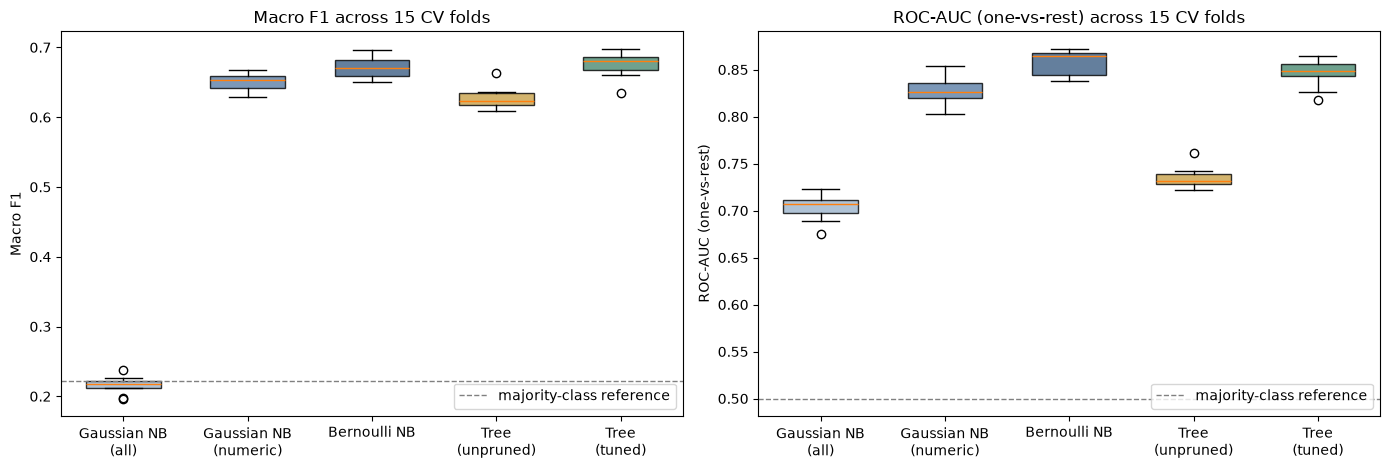

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
names = list(results)[1:]
short = ['Gaussian NB\n(all)', 'Gaussian NB\n(numeric)', 'Bernoulli NB', 'Tree\n(unpruned)', 'Tree\n(tuned)']
for ax, metric, title in zip(axes, ['f1_macro', 'roc_auc_ovr'], ['Macro F1', 'ROC-AUC (one-vs-rest)']):
    bp = ax.boxplot([results[n][f'test_{metric}'] for n in names], tick_labels=short, patch_artist=True, widths=.6)
    for patch, colour in zip(bp['boxes'], ['#9db4cc', '#5b7fa6', '#3d5f85', '#c9a14a', '#4b8a72']):
        patch.set(facecolor=colour, alpha=.8)
    ax.axhline(results['Majority class (reference)'][f'test_{metric}'].mean(), color='grey', ls='--', lw=1, label='majority-class reference')
    ax.set(title=f'{title} across 15 CV folds', ylabel=title)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [9]:
# Paired comparison on identical folds, with the Nadeau-Bengio correction for overlapping training sets
def corrected_paired_t(a, b, n_test_over_train=0.25):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test_over_train) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=k - 1)

pairs = [('Decision tree (tuned, nested CV)', 'Bernoulli Naive Bayes (binned)'),
         ('Decision tree (tuned, nested CV)', 'Gaussian NB (numeric only)'),
         ('Bernoulli Naive Bayes (binned)', 'Gaussian NB (numeric only)'),
         ('Gaussian NB (numeric only)', 'Gaussian NB (all features)'),
         ('Decision tree (tuned, nested CV)', 'Decision tree (unpruned)')]
rows = []
for a, b in pairs:
    for metric in ['f1_macro', 'roc_auc_ovr']:
        diff, t, p = corrected_paired_t(results[a][f'test_{metric}'], results[b][f'test_{metric}'])
        rows.append({'A': a, 'B': b, 'metric': metric, 'mean(A-B)': round(diff, 4), 't': round(t, 2), 'p (corrected)': round(p, 4)})
display(pd.DataFrame(rows))

,A,B,metric,mean(A-B),t,p (corrected)
0,"Decision tree (tuned, nested CV)",Bernoulli Naive Bayes (binned),f1_macro,0.0046,0.41,0.6873
1,"Decision tree (tuned, nested CV)",Bernoulli Naive Bayes (binned),roc_auc_ovr,-0.0112,-1.52,0.1500
2,"Decision tree (tuned, nested CV)",Gaussian NB (numeric only),f1_macro,0.0249,2.19,0.0456
3,"Decision tree (tuned, nested CV)",Gaussian NB (numeric only),roc_auc_ovr,0.0196,2.45,0.0280
4,Bernoulli Naive Bayes (binned),Gaussian NB (numeric only),f1_macro,0.0203,3.10,0.0079
5,Bernoulli Naive Bayes (binned),Gaussian NB (numeric only),roc_auc_ovr,0.0308,6.85,0.0000
6,Gaussian NB (numeric only),Gaussian NB (all features),f1_macro,0.4339,57.25,0.0000
7,Gaussian NB (numeric only),Gaussian NB (all features),roc_auc_ovr,0.1240,11.25,0.0000
8,"Decision tree (tuned, nested CV)",Decision tree (unpruned),f1_macro,0.0490,4.67,0.0004
9,"Decision tree (tuned, nested CV)",Decision tree (unpruned),roc_auc_ovr,0.1131,15.31,0.0000


## 4. Decision-tree behaviour: depth, overfitting and the tuned configuration

The validation curve below uses 5-fold CV on the training partition. It is a diagnostic: the tuned model that is *scored* above chose its depth inside nested CV.

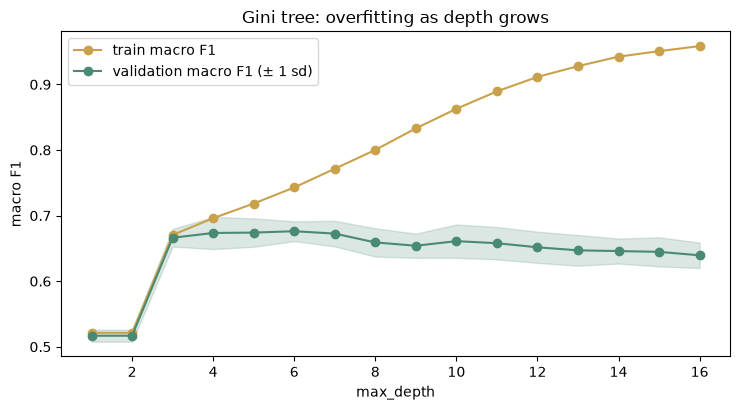

Best validation depth: 6


In [10]:
depths = list(range(1, 17))
train_scores, val_scores = validation_curve(
    with_model(continuous_preprocessing(), DecisionTreeClassifier(random_state=SEED)), X_train, y_train,
    param_name='model__max_depth', param_range=depths, scoring='f1_macro',
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(depths, train_scores.mean(axis=1), 'o-', color='#c9a14a', label='train macro F1')
ax.fill_between(depths, val_scores.mean(axis=1) - val_scores.std(axis=1), val_scores.mean(axis=1) + val_scores.std(axis=1), color='#4b8a72', alpha=.2)
ax.plot(depths, val_scores.mean(axis=1), 'o-', color='#4b8a72', label='validation macro F1 (± 1 sd)')
ax.set(xlabel='max_depth', ylabel='macro F1', title='Gini tree: overfitting as depth grows')
ax.legend()
plt.tight_layout()
plt.show()
print('Best validation depth:', depths[int(val_scores.mean(axis=1).argmax())])

Selected hyperparameters: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 30}
Inner 5-fold macro F1 of the selected configuration: 0.6805


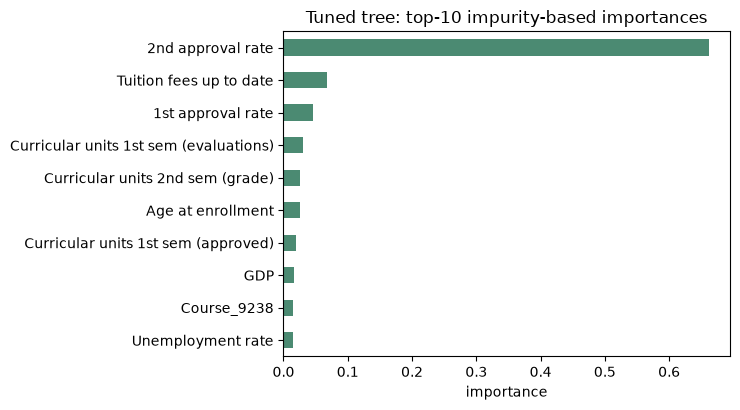

In [11]:
search = tuned_tree_search(cv=5).fit(X_train, y_train)   # final tuning on the full training partition
print('Selected hyperparameters:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f'Inner 5-fold macro F1 of the selected configuration: {search.best_score_:.4f}')
tuned_tree = search.best_estimator_
prep_final = tuned_tree.named_steps['prep']
names_out = [n.split('__', 1)[1] for n in prep_final.named_steps['preprocess'].get_feature_names_out()]
importance = pd.Series(tuned_tree.named_steps['model'].feature_importances_, index=names_out).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
importance.head(10)[::-1].plot.barh(ax=ax, color='#4b8a72')
ax.set(title='Tuned tree: top-10 impurity-based importances', xlabel='importance')
plt.tight_layout()
plt.show()

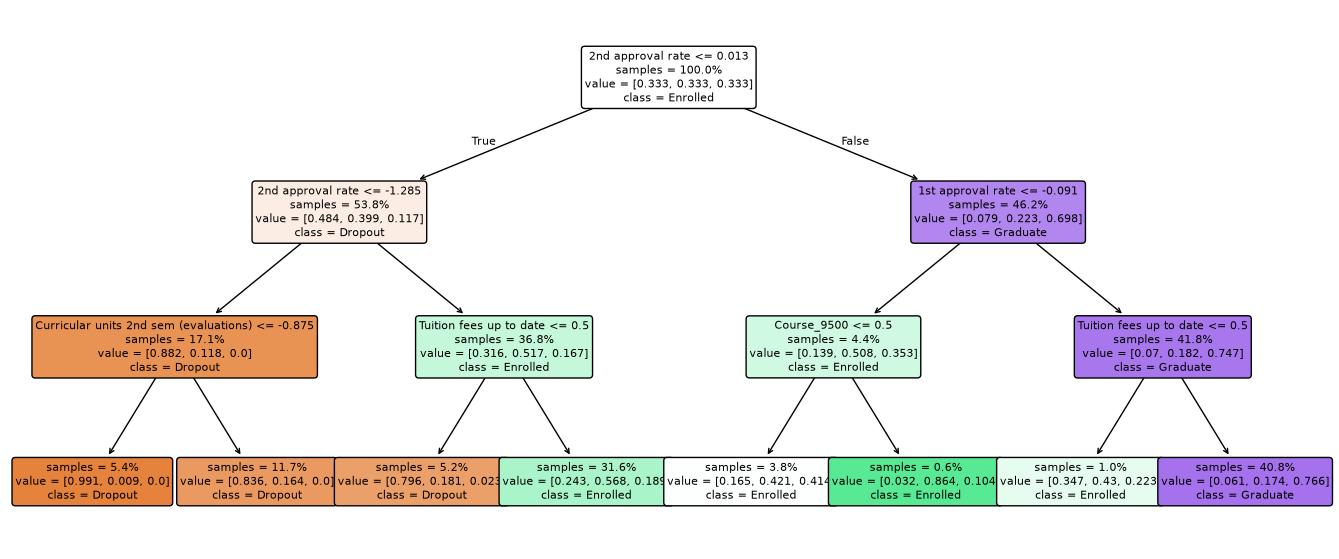

In [12]:
# Illustrative depth-3 tree (readable); not the tuned model
shallow = with_model(continuous_preprocessing(), DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(shallow.named_steps['model'], feature_names=[n.split('__', 1)[1] for n in shallow.named_steps['prep'].named_steps['preprocess'].get_feature_names_out()],
          class_names=shallow.named_steps['model'].classes_, filled=True, rounded=True, fontsize=8, impurity=False, proportion=True, ax=ax)
plt.show()

## 5. Fit the Naive Bayes models and the tuned tree on the full training partition

In [13]:
final_models = {
    'Gaussian NB (all features)': MODELS['Gaussian NB (all features)'],
    'Gaussian NB (numeric only)': MODELS['Gaussian NB (numeric only)'],
    'Bernoulli Naive Bayes (binned)': MODELS['Bernoulli Naive Bayes (binned)'],
    'Decision tree (tuned)': tuned_tree,
}
for name, model in final_models.items():
    if name != 'Decision tree (tuned)':
        model.fit(X_train, y_train)
    print('fitted:', name)

fitted: Gaussian NB (all features)
fitted: Gaussian NB (numeric only)
fitted: Bernoulli Naive Bayes (binned)
fitted: Decision tree (tuned)


## 6. Held-out test evaluation (one look, after all choices are fixed)

Every model choice above used only the training partition. The test set is scored once here, to confirm that the cross-validation estimates carry over to unseen students.

In [14]:
rows, preds = [], {}
for name, model in final_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    preds[name] = pred
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced acc.': balanced_accuracy_score(y_test, pred),
        'Macro F1': f1_score(y_test, pred, average='macro'),
        'ROC-AUC (OvR)': roc_auc_score(y_test, proba, multi_class='ovr', average='macro', labels=model.classes_),
        **{f'Recall {c}': class_recall(y_test, pred, c) for c in CLASSES},
    })
test_table = pd.DataFrame(rows).set_index('Model').round(3)
display(test_table)
print(classification_report(y_test, preds['Decision tree (tuned)'], digits=3))

,Accuracy,Balanced acc.,Macro F1,ROC-AUC (OvR),Recall Dropout,Recall Enrolled,Recall Graduate
Model,,,,,,,
Gaussian NB (all features),0.245,0.393,0.219,0.707,0.204,0.962,0.014
Gaussian NB (numeric only),0.720,0.659,0.660,0.843,0.588,0.509,0.880
Bernoulli Naive Bayes (binned),0.719,0.688,0.678,0.860,0.658,0.610,0.796
Decision tree (tuned),0.707,0.688,0.674,0.848,0.648,0.648,0.767


              precision    recall  f1-score   support

     Dropout      0.852     0.648     0.736       284
    Enrolled      0.376     0.648     0.476       159
    Graduate      0.858     0.767     0.810       442

    accuracy                          0.707       885
   macro avg      0.695     0.688     0.674       885
weighted avg      0.770     0.707     0.726       885



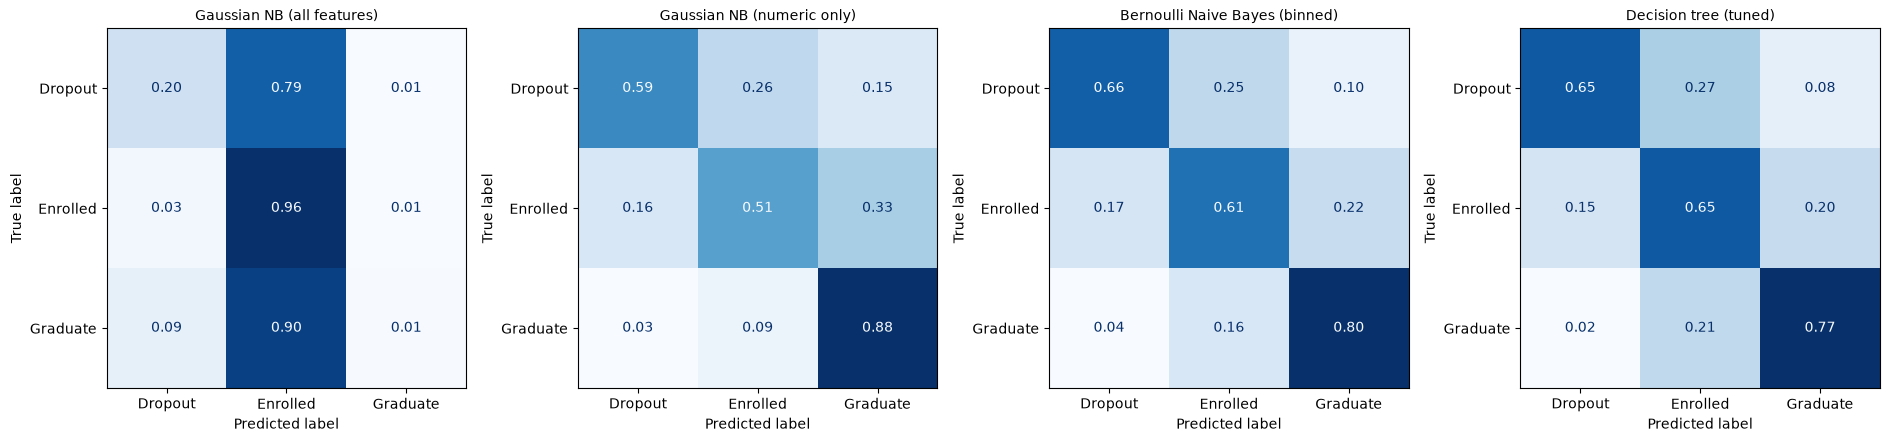

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASSES, normalize='true', cmap='Blues',
                                            values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## 7. Comparison and discussion

**Headline result.** On this dataset a Bernoulli Naive Bayes model and a tuned decision tree are statistically tied, and both beat the other candidates. In nested 5×3 cross-validation the tuned tree scored macro F1 0.676 ± 0.015 against 0.671 ± 0.013 for Bernoulli NB. The paired, Nadeau–Bengio-corrected test on identical folds gives a mean difference of 0.005 (p = 0.69), and ROC-AUC (0.847 vs 0.858, p = 0.15) does not separate them either. On the held-out test set the same picture holds: macro F1 0.674 (tree) vs 0.678 (Bernoulli NB), ROC-AUC 0.848 vs 0.860. We therefore do **not** claim that either model is better; the evidence only supports that they are about equally good, with macro F1 near 0.67 and accuracy near 0.71–0.72.

**Why the tree benefits from tuning.** An unpruned tree memorises the training data (training macro F1 approaches 0.96 at depth 16 while validation F1 peaks near depth 6 and then declines, see the validation curve). Its nested-CV macro F1 of 0.626 is significantly worse than the tuned tree's 0.676 (p < 0.001), and its ROC-AUC of 0.734 is far lower because its leaves are nearly pure, so its probability estimates are almost all 0 or 1. The selected configuration (entropy criterion, depth 8, at least 30 samples per leaf, balanced class weights) regularises the tree. Enrolled recall rises from 0.38 (unpruned) to 0.55 (tuned) in cross-validation; class weighting and the shallower, larger-leaf tree both plausibly contribute, but we did not run an ablation to separate them.

**Why Naive Bayes behaves as it does here.** Naive Bayes assumes the features are conditionally independent given the class. This is clearly violated: first- and second-semester course counts and grades are strongly related, as are the parents' education and occupation codes. Despite this, NB ranks students well (ROC-AUC 0.83–0.86) because it only needs the *ordering* of its posteriors to be good, not calibrated probabilities. Two representation choices mattered far more than the NB variant itself:

* Gaussian NB on the full Part 1 matrix is the worst model in the study (macro F1 0.217, below the majority-class reference 0.222; on the test set it assigns about 88 % of students to `Enrolled`). The diagnostic in Section 1.1 shows why: 34 % of the within-class variances of the 239 columns are below 10⁻³, because the one-hot columns are almost always 0. A normal density this narrow makes any rare category value an overwhelming piece of evidence.
* Restricting Gaussian NB to the 21 numeric columns lifts macro F1 to 0.651 (p < 0.01 below Bernoulli NB). Representing everything as 0/1 indicators with quantile-binned numerics for Bernoulli NB lifts it further to 0.671, plausibly because binning lets NB represent non-normal, threshold-like effects. The hand-worked split shows one such effect: only 8 % of students with at most 3 approved second-semester units graduate (96 of 1,175), against 71 % of the rest (1,671 of 2,364). We did not test this explanation separately from the effect of the extra 0/1 columns.

**Per-class behaviour.** Both leading models are strong on `Graduate` (recall 0.77–0.80 on test) and `Dropout` (0.65–0.66, precision 0.85 for the tree), and weak on `Enrolled`, the smallest and most heterogeneous class: the tuned tree's test precision for `Enrolled` is only 0.38, even though its recall is 0.65. This is the predictable cost of class weighting and of a class whose members look like both of the other groups. Improving the `Enrolled` class, rather than overall accuracy, is the main opportunity for Part 3.

**Which model would we choose?** On accuracy of prediction, neither. For interpretability and for deployment as a rule-based screen, the tree, because its decisions can be read off and explained to staff. Its importances are dominated by the second-semester approval rate (about 0.66 of the total), a feature built in Part 1, followed by tuition fees up to date and the first-semester approval rate. For the best ranking quality and the fastest, most stable training (about 0.1 s per fit versus 24 s for the nested tuning), Bernoulli NB. Both rely on second-semester information, so they are end-of-year-one early-warning tools, not enrollment-time predictors. Part 3's ensembles and systematic tuning should show whether the ceiling near 0.68 macro F1 is a property of the data or of these simple baselines.

*Caveats.* Cross-validation standard deviations are across overlapping folds, so the corrected paired test, not the raw standard deviation, is the right basis for "tied" or "different". The test set (885 students, 159 `Enrolled`) is small enough that differences of ±0.01 in macro F1 are within noise.
